# Final 02 — Clusterização de risco

Mesma lógica do `04_clusterizacao_risco`, com as features de `final/01_ydata_selecao`.

Pipeline para os 3 algoritmos:
1. **Treino**: grid search + CV (Silhouette) da classe `Clustering`. O **melhor parâmetro** de cada
   algoritmo é o escolhido.
2. **Validação** e **teste**: hiperparâmetros **congelados**, dados escalonados com o scaler do
   **treino**. Métricas com os rótulos **projetados** (modelo do treino aplicado no conjunto novo),
   ARI projeção × refit e qui² de aderência.

In [1]:
import json
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chisquare
from sklearn.cluster import DBSCAN, AgglomerativeClustering, KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (adjusted_rand_score, calinski_harabasz_score, davies_bouldin_score,
                             silhouette_score)
from sklearn.neighbors import KNeighborsClassifier, NearestCentroid
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)


def encontrar_raiz_repo(marcadores=(".git", "data")):
    for pasta in [Path.cwd(), *Path.cwd().parents]:
        if all((pasta / m).exists() for m in marcadores):
            return pasta
    raise FileNotFoundError(f"Nao achei {marcadores} subindo a partir de {Path.cwd()}")


RAIZ = encontrar_raiz_repo()
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

from notebooks.src.clustering import Clustering
from notebooks.src.graficos import CONJUNTOS, grafico_metricas

RANDOM_STATE = 42
pd.set_option("display.width", 200)

## 1. Dados

In [2]:
pasta = RAIZ / "data/processed/df_estruturada"
df_train = pd.read_csv(pasta / "df_train_risco.csv", index_col=0)
df_valid = pd.read_csv(pasta / "df_valid_risco.csv", index_col=0)
df_test = pd.read_csv(pasta / "df_test_risco.csv", index_col=0)

selecao = json.loads((RAIZ / "data/processed/final/features_selecionadas.json").read_text())
FEATURES = selecao["features_finais"]
DESCRITIVAS = selecao["descritivas"]   # não entram no clustering, só na descrição dos clusters

print(f"treino: {len(df_train)} | validação: {len(df_valid)} | teste: {len(df_test)}")
print("FEATURES:", FEATURES)
print("DESCRITIVAS:", DESCRITIVAS)


def agrupa_especie(s, minimo=14):
    return s.where(s.map(s.value_counts()) >= minimo, "outras")


esp_train = agrupa_especie(df_train["Species"])

treino: 1558 | validação: 445 | teste: 223
FEATURES: ['has_mbl', 'has_carbapenemase_serina', 'has_esbl', 'has_16s_metilase', 'has_pmqr', 'n_classes_adquiridas', 'pct_adquiridos_plasmidial']
DESCRITIVAS: ['has_carbapenemase', 'carbapenemase_plasmidial', 'n_bl_adquiridas', 'n_genes_adquiridos', 'has_ampc_adquirida', 'has_mcr']


### `StandardScaler` — ajustado SÓ no treino

O mesmo scaler (média e DP do treino) transforma validação e teste: os centróides vivem no espaço
do treino, então os genomas novos precisam ser medidos com a mesma régua.

In [3]:
scaler = StandardScaler().fit(df_train[FEATURES])
X = {nome: scaler.transform(df[FEATURES]) for nome, df in zip(CONJUNTOS, [df_train, df_valid, df_test])}
pd.DataFrame({"média (treino)": scaler.mean_, "DP (treino)": scaler.scale_}, index=FEATURES).round(3)

,média (treino),DP (treino)
has_mbl,0.116,0.320
has_carbapenemase_serina,0.567,0.496
has_esbl,0.485,0.500
has_16s_metilase,0.137,0.344
has_pmqr,0.236,0.425
n_classes_adquiridas,4.423,2.169
pct_adquiridos_plasmidial,0.594,0.312


## 2. Treino — grid search + CV (Silhouette)

`Clustering.cross_validation` testa cada combinação do grid com `KFold(5)` e devolve a tabela com o
silhouette médio de CV. O melhor de cada algoritmo é o parâmetro escolhido.

In [4]:
def limpar(params):
    # floats inteiros (ex.: n_clusters = 6.0) voltam a int; numpy -> tipo nativo (json)
    saida = {}
    for k, v in params.items():
        if isinstance(v, (float, np.floating)) and float(v).is_integer() and k != "eps":
            v = int(v)
        elif isinstance(v, np.generic):
            v = v.item()
        saida[k] = v
    return saida


grids, PARAMS_ESCOLHIDOS = {}, {}
for modelo in ["kmeans", "agglomerative", "dbscan"]:
    _, _, _, df_grid = Clustering(features=FEATURES, df=df_train, modelo=modelo).cross_validation(print_metricas=False)
    grids[modelo] = df_grid.sort_values("mean_score", ascending=False)
    param_cols = [c for c in df_grid.columns if c not in ("mean_score", "std_score")]
    melhor = grids[modelo].iloc[0]
    PARAMS_ESCOLHIDOS[modelo] = limpar({c: melhor[c] for c in param_cols})

PARAMS_ESCOLHIDOS

{'kmeans': {'n_clusters': 8, 'init': 'k-means++', 'n_init': 10},
 'agglomerative': {'n_clusters': 8, 'metric': 'euclidean', 'linkage': 'ward'},
 'dbscan': {'eps': 1.0, 'min_samples': 3, 'metric': 'euclidean'}}

In [5]:
for modelo, g in grids.items():
    print(f"\n=== {modelo} (top 5 por silhouette CV) ===")
    print(g.head(5).round(4).to_string(index=False))


=== kmeans (top 5 por silhouette CV) ===
 n_clusters      init  n_init  mean_score  std_score
          8 k-means++      10      0.4409     0.0201
          8 k-means++      20      0.4390     0.0198
          8    random      20      0.4350     0.0205
          8    random      10      0.4349     0.0213
          7 k-means++      20      0.4163     0.0237

=== agglomerative (top 5 por silhouette CV) ===
 n_clusters    metric linkage  mean_score  std_score
          8 euclidean    ward      0.4379     0.0211
          7 euclidean    ward      0.4106     0.0221
          6 euclidean    ward      0.3959     0.0187
          5 euclidean    ward      0.3796     0.0217
          7 euclidean average      0.3737     0.0268

=== dbscan (top 5 por silhouette CV) ===
 eps  min_samples    metric  mean_score  std_score
 1.0            3 euclidean      0.5039     0.0194
 1.0            3 manhattan      0.4913     0.0340
 1.5            3 manhattan      0.4795     0.0405
 0.7            3 euclidean

In [6]:
def instanciar(modelo, params):
    if modelo == "kmeans":
        return KMeans(**params, random_state=RANDOM_STATE)
    if modelo == "dbscan":
        return DBSCAN(**params)
    return AgglomerativeClustering(**params)


modelos_treinados, labels_train = {}, {}
for modelo, params in PARAMS_ESCOLHIDOS.items():
    fit = instanciar(modelo, params).fit(X["treino"])
    modelos_treinados[modelo] = fit
    labels_train[modelo] = fit.labels_
    tamanhos = pd.Series(fit.labels_).value_counts().sort_index()
    print(f"{modelo:14s} {len(set(fit.labels_) - {-1})} clusters | menor: {tamanhos.drop(-1, errors='ignore').min()} "
          f"| ruído: {(fit.labels_ == -1).mean():.1%}")

kmeans         8 clusters | menor: 136 | ruído: 0.0%
agglomerative  8 clusters | menor: 129 | ruído: 0.0%
dbscan         22 clusters | menor: 4 | ruído: 1.2%


### 2.1 Os 3 algoritmos concordam? E com a espécie?

ARI entre as partições do treino (premissas diferentes: centróide, hierarquia, densidade) e de cada
uma com a espécie (queremos **baixo**: o cluster não deve ser a espécie).

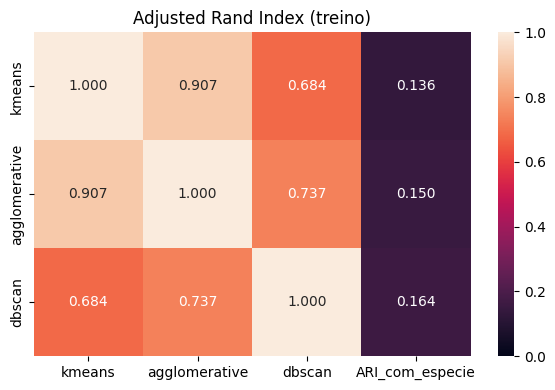

,kmeans,agglomerative,dbscan,ARI_com_especie
kmeans,1.000,0.907,0.684,0.136
agglomerative,0.907,1.000,0.737,0.150
dbscan,0.684,0.737,1.000,0.164


In [7]:
nomes = list(labels_train)
concordancia = pd.DataFrame([[adjusted_rand_score(labels_train[a], labels_train[b]) for b in nomes] for a in nomes],
                            index=nomes, columns=nomes)
concordancia["ARI_com_especie"] = [adjusted_rand_score(esp_train, labels_train[m]) for m in nomes]

plt.figure(figsize=(6, 4))
sns.heatmap(concordancia, annot=True, fmt=".3f", vmin=0, vmax=1)
plt.title("Adjusted Rand Index (treino)")
plt.tight_layout()
plt.show()
concordancia.round(3)

## 3. Métricas no treino, na validação e no teste

- **Projeção** (modelo do treino → conjunto novo): `predict` no KMeans, centróide mais próximo no
  Agglomerative, 1-vizinho mais próximo no DBSCAN (os dois últimos não têm `predict`).
- **Silhouette / Davies-Bouldin / Calinski-Harabasz**: calculados com os rótulos **projetados**
  (sem o ruído do DBSCAN).
- **ARI projeção × refit**: um modelo novo, com os mesmos hiperparâmetros, ajustado só no conjunto
  novo, dá a mesma partição?
- **Qui² de aderência**: a proporção de cada cluster no conjunto novo bate com a do treino?
  `min_esperado` < 5 invalida a aproximação do qui².

In [8]:
def metricas_internas(X_, labels):
    mask = labels != -1
    if len(set(labels[mask])) < 2:
        return np.nan, np.nan, np.nan
    return (silhouette_score(X_[mask], labels[mask]), davies_bouldin_score(X_[mask], labels[mask]),
            calinski_harabasz_score(X_[mask], labels[mask]))


def projetar(modelo, X_novo):
    fit = modelos_treinados[modelo]
    if modelo == "kmeans":
        return fit.predict(X_novo)
    if modelo == "agglomerative":
        return NearestCentroid().fit(X["treino"], fit.labels_).predict(X_novo)
    return KNeighborsClassifier(n_neighbors=1).fit(X["treino"], fit.labels_).predict(X_novo)


def qui2(labels_tr, labels_proj):
    todos = np.unique(np.concatenate([labels_tr, labels_proj]))
    esperado = pd.Series(labels_tr).value_counts().reindex(todos, fill_value=0) / len(labels_tr) * len(labels_proj)
    observado = pd.Series(labels_proj).value_counts().reindex(todos, fill_value=0)
    _, p = chisquare(observado, esperado)
    return p, esperado.min()


linhas = []
for modelo, params in PARAMS_ESCOLHIDOS.items():
    for conjunto in CONJUNTOS:
        if conjunto == "treino":
            lab = labels_train[modelo]
            n_refit, ari, p, min_esp = len(set(lab) - {-1}), 1.0, np.nan, np.nan
        else:
            lab = projetar(modelo, X[conjunto])
            refit = instanciar(modelo, params).fit_predict(X[conjunto])
            n_refit = len(set(refit) - {-1})
            ari = adjusted_rand_score(lab, refit)
            p, min_esp = qui2(labels_train[modelo], lab)
        ss, dbs, chs = metricas_internas(X[conjunto], lab)
        linhas.append({"modelo": modelo, "conjunto": conjunto, "n_clusters": n_refit,
                       "frac_ruido": (lab == -1).mean(), "silhouette": ss, "davies_bouldin": dbs,
                       "calinski_harabasz": chs, "ari_projecao_x_refit": ari, "qui2_p": p,
                       "min_esperado": min_esp})

resumo = pd.DataFrame(linhas).set_index(["modelo", "conjunto"])
resumo.round(3)

n_clusters  frac_ruido  silhouette  davies_bouldin  calinski_harabasz  ari_projecao_x_refit  qui2_p  min_esperado
modelo        conjunto                                                                                                                    
kmeans        treino              8       0.000       0.445           0.887            653.227                 1.000     NaN           NaN
              validação           8       0.000       0.446           0.840            192.244                 0.997   0.007        38.845
              teste               8       0.000       0.466           0.808            104.031                 0.973   0.567        19.466
agglomerative treino              8       0.000       0.431           0.977            602.579                 1.000     NaN           NaN
              validação           8       0.000       0.448           0.853            190.952                 0.970   0.004        36.845
              teste               8       0.000       0.468           0.818            103.927                 0.983   0.945        18.464
dbscan        treino             22       0.012       0.484           0.769            294.241                 1.000     NaN           NaN
              validação          15       0.009       0.483           0.699             82.548                 0.894   0.380         1.142
              teste              11       0.004       0.458           0.661             42.575                 0.830   0.984         0.573

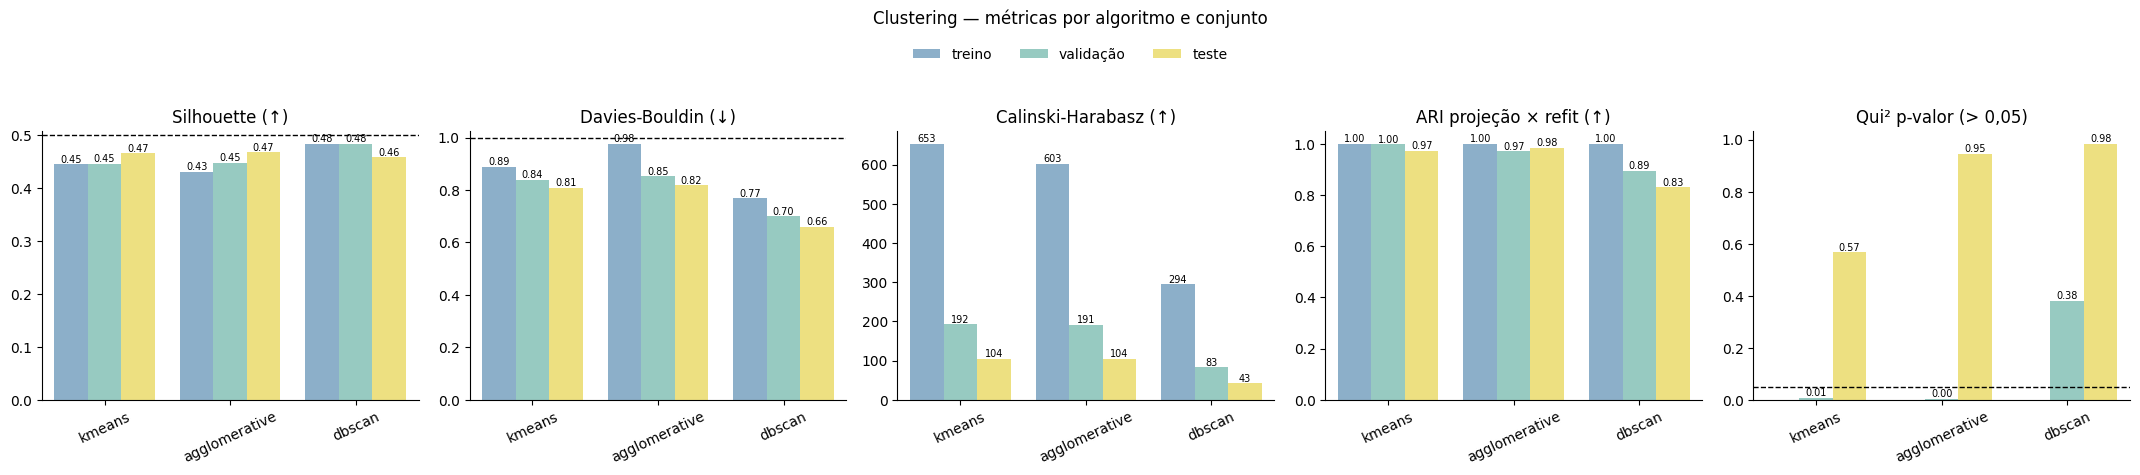

In [9]:
METRICAS_CLUSTER = {
    "silhouette": "Silhouette (↑)",
    "davies_bouldin": "Davies-Bouldin (↓)",
    "calinski_harabasz": "Calinski-Harabasz (↑)",
    "ari_projecao_x_refit": "ARI projeção × refit (↑)",
    "qui2_p": "Qui² p-valor (> 0,05)",
}
grafico_metricas(resumo.reset_index(), METRICAS_CLUSTER, "Clustering — métricas por algoritmo e conjunto",
                 referencias={"silhouette": 0.5, "davies_bouldin": 1, "qui2_p": 0.05},
                 formatos={"calinski_harabasz": "%.0f"})
plt.show()

**Calinski-Harabasz cresce com o nº de genomas**: só compare algoritmos dentro do mesmo conjunto,
não treino (1558) com validação (445) ou teste (223).

## 4. Perfil dos clusters (KMeans, treino)

KMeans é o **modelo final**: tem `predict` nativo, então um genoma novo é classificado direto.

Cor = z-score da média do cluster em relação ao treino (as features têm escalas diferentes);
número = média real. Acima da linha preta, as features do clustering; abaixo, as descritivas.

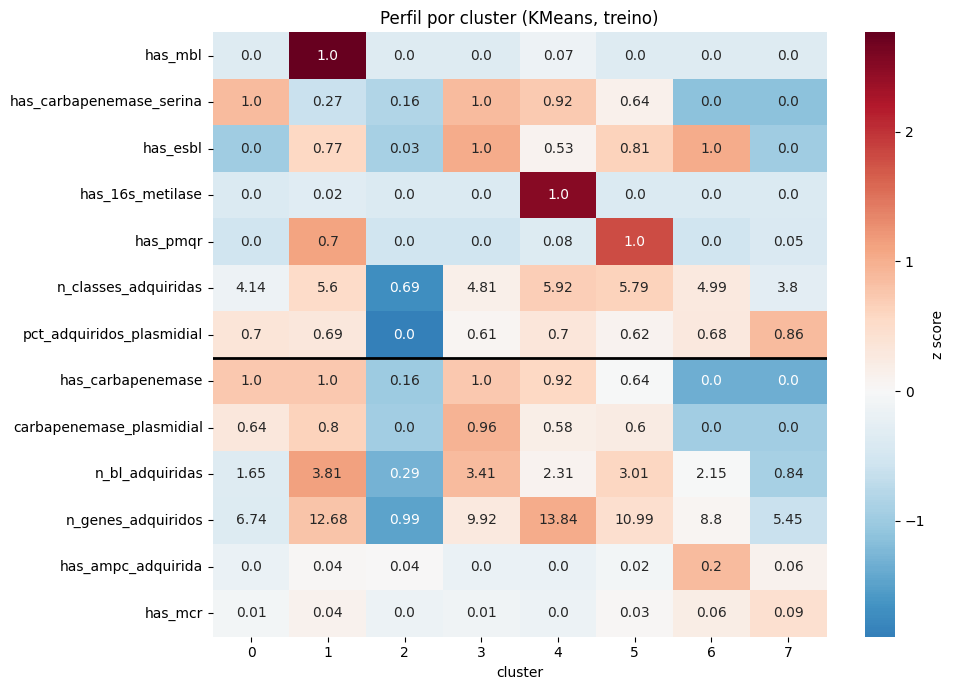

,0,1,2,3,4,5,6,7
has_mbl,0.00,1.00,0.00,0.00,0.07,0.00,0.00,0.00
has_carbapenemase_serina,1.00,0.27,0.16,1.00,0.92,0.64,0.00,0.00
has_esbl,0.00,0.77,0.03,1.00,0.53,0.81,1.00,0.00
has_16s_metilase,0.00,0.02,0.00,0.00,1.00,0.00,0.00,0.00
has_pmqr,0.00,0.70,0.00,0.00,0.08,1.00,0.00,0.05
n_classes_adquiridas,4.14,5.60,0.69,4.81,5.92,5.79,4.99,3.80
pct_adquiridos_plasmidial,0.70,0.69,0.00,0.61,0.70,0.62,0.68,0.86
has_carbapenemase,1.00,1.00,0.16,1.00,0.92,0.64,0.00,0.00
carbapenemase_plasmidial,0.64,0.80,0.00,0.96,0.58,0.60,0.00,0.00
n_bl_adquiridas,1.65,3.81,0.29,3.41,2.31,3.01,2.15,0.84


In [10]:
lab_km = labels_train["kmeans"]
perfil = df_train.groupby(lab_km)[FEATURES + DESCRITIVAS].mean()
perfil["n"] = pd.Series(lab_km).value_counts().sort_index().values

z = (perfil[FEATURES + DESCRITIVAS] - df_train[FEATURES + DESCRITIVAS].mean()) / df_train[FEATURES + DESCRITIVAS].std()
fig, ax = plt.subplots(figsize=(10, 7))
sns.heatmap(z.T, cmap="RdBu_r", center=0, annot=perfil[FEATURES + DESCRITIVAS].T.round(2), fmt="", ax=ax,
            cbar_kws={"label": "z score"})
ax.axhline(len(FEATURES), c="k", lw=2)
ax.set(title="Perfil por cluster (KMeans, treino)", xlabel="cluster")
plt.tight_layout()
plt.show()
perfil.T.round(2)

### 4.1 Nome de cada cluster

Um mecanismo entra no nome quando **≥ 70% do cluster** o possui. Entre parênteses, a fração média
dos genes adquiridos em plasmídeo e o nº médio de classes de droga.

In [11]:
MECANISMOS = {"has_carbapenemase_serina": "carbapenemase serina", "has_mbl": "MBL", "has_esbl": "ESBL",
              "has_16s_metilase": "metilase 16S", "has_pmqr": "PMQR"}


def nomear(p, limiar=0.7):
    partes = [nome for col, nome in MECANISMOS.items() if col in p and p[col] >= limiar]
    base = " + ".join(partes) if partes else "sem mecanismo principal adquirido"
    return f"C{p.name}: {base} (plasm. {p['pct_adquiridos_plasmidial']:.0%}, {p['n_classes_adquiridas']:.1f} classes)"


NOMES = {c: nomear(perfil.loc[c]) for c in perfil.index}
pd.Series(NOMES, name="perfil").to_frame().join(perfil["n"])

,perfil,n
0,"C0: carbapenemase serina (plasm. 70%, 4.1 clas...",276
1,"C1: MBL + ESBL + PMQR (plasm. 69%, 5.6 classes)",164
2,C2: sem mecanismo principal adquirido (plasm. ...,216
3,"C3: carbapenemase serina + ESBL (plasm. 61%, 4...",191
4,C4: carbapenemase serina + metilase 16S (plasm...,210
5,"C5: ESBL + PMQR (plasm. 62%, 5.8 classes)",228
6,"C6: ESBL (plasm. 68%, 5.0 classes)",136
7,C7: sem mecanismo principal adquirido (plasm. ...,137


Dois clusters ficam "sem mecanismo principal adquirido", mas são diferentes: **C2** quase não tem
gene adquirido (0,7 classe, nada em plasmídeo; *E. coli* sensível) e **C7** tem ~4 classes de droga
adquiridas, 86% em plasmídeo, só que nenhuma das beta-lactamases/metilase/PMQR principais.

### 4.2 Os clusters atravessam espécies?

In [12]:
ct = pd.crosstab(esp_train, pd.Series(lab_km, index=df_train.index).map(NOMES))
print(f"ARI cluster x espécie = {adjusted_rand_score(esp_train, lab_km):.3f}  (0 = independente, 1 = cluster é a espécie)")
ct

ARI cluster x espécie = 0.136  (0 = independente, 1 = cluster é a espécie)


col_0,"C0: carbapenemase serina (plasm. 70%, 4.1 classes)","C1: MBL + ESBL + PMQR (plasm. 69%, 5.6 classes)","C2: sem mecanismo principal adquirido (plasm. 0%, 0.7 classes)","C3: carbapenemase serina + ESBL (plasm. 61%, 4.8 classes)","C4: carbapenemase serina + metilase 16S (plasm. 70%, 5.9 classes)","C5: ESBL + PMQR (plasm. 62%, 5.8 classes)","C6: ESBL (plasm. 68%, 5.0 classes)","C7: sem mecanismo principal adquirido (plasm. 86%, 3.8 classes)"
Species,,,,,,,,
Acinetobacter baumannii,144,11,38,1,90,0,1,4
Enterobacter hormaechei,0,11,1,1,3,9,1,0
Escherichia coli,8,11,127,2,2,36,80,104
Klebsiella aerogenes,0,2,4,0,1,7,0,1
Klebsiella pneumoniae,102,87,21,186,113,166,45,19
Klebsiella quasipneumoniae,3,18,2,0,0,1,1,0
Proteus mirabilis,1,1,6,0,0,0,4,2
Serratia marcescens,14,1,5,0,0,0,3,2
outras,4,22,12,1,1,9,1,5


### 4.3 Projeção PCA

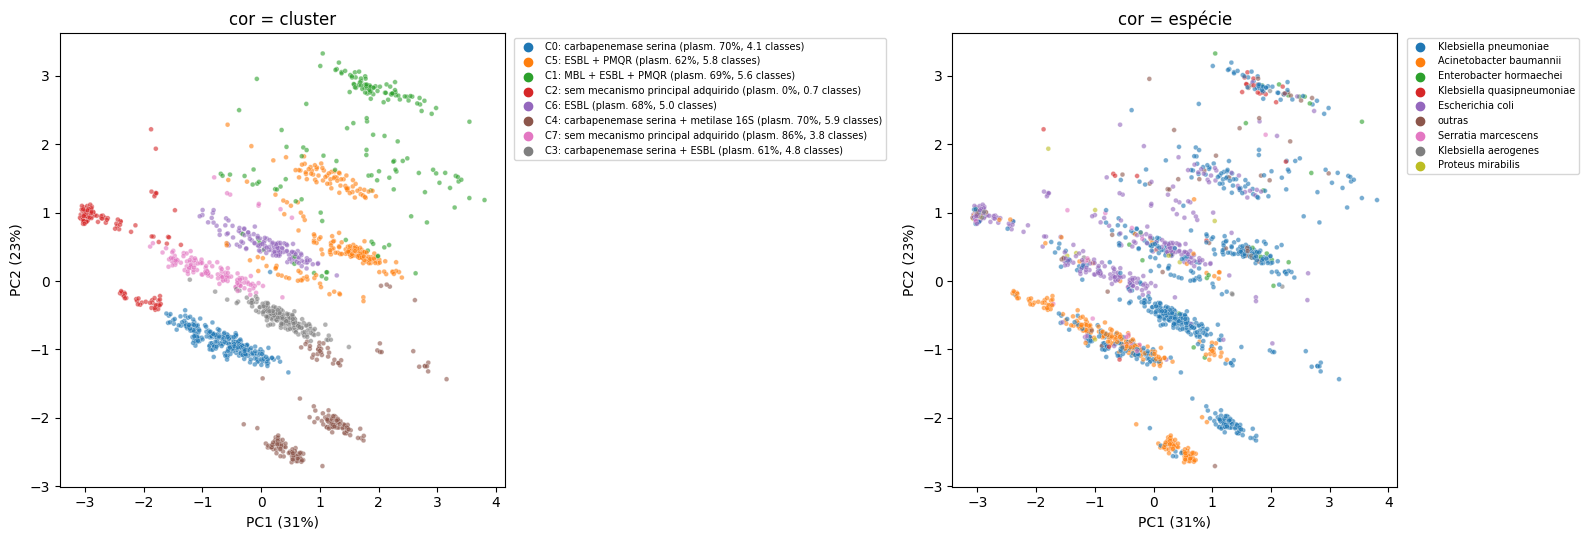

In [13]:
rng = np.random.default_rng(RANDOM_STATE)
pca = PCA(n_components=2, random_state=RANDOM_STATE).fit(X["treino"])
coords = pca.transform(X["treino"]) + rng.normal(0, 0.05, (len(X["treino"]), 2))   # jitter: pontos repetidos
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
sns.scatterplot(x=coords[:, 0], y=coords[:, 1], hue=pd.Series(lab_km).map(NOMES).values, s=12, alpha=0.6, ax=axes[0])
sns.scatterplot(x=coords[:, 0], y=coords[:, 1], hue=esp_train.values, s=12, alpha=0.6, ax=axes[1])
for ax, t in zip(axes, ["cor = cluster", "cor = espécie"]):
    ax.set(xlabel=f"PC1 ({pca.explained_variance_ratio_[0]:.0%})", ylabel=f"PC2 ({pca.explained_variance_ratio_[1]:.0%})", title=t)
    ax.legend(fontsize=7, bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.show()

### 4.4 O perfil se repete na validação e no teste?

Perfil médio de cada cluster com o rótulo projetado pelo KMeans do treino.

In [14]:
lab_proj = {"validação": projetar("kmeans", X["validação"]), "teste": projetar("kmeans", X["teste"])}
perfis = {"treino": perfil[FEATURES]}
perfis.update({c: df.groupby(lab_proj[c])[FEATURES].mean() for c, df in [("validação", df_valid), ("teste", df_test)]})
for c in ["validação", "teste"]:
    print(f"maior diferença absoluta treino x {c}:", (perfis["treino"] - perfis[c]).abs().max().round(3).to_dict())
pd.concat(perfis, axis=1).swaplevel(axis=1).sort_index(axis=1).round(2)

maior diferença absoluta treino x validação: {'has_mbl': 0.016, 'has_carbapenemase_serina': 0.012, 'has_esbl': 0.052, 'has_16s_metilase': 0.01, 'has_pmqr': 0.058, 'n_classes_adquiridas': 0.546, 'pct_adquiridos_plasmidial': 0.121}
maior diferença absoluta treino x teste: {'has_mbl': 0.04, 'has_carbapenemase_serina': 0.116, 'has_esbl': 0.078, 'has_16s_metilase': 0.014, 'has_pmqr': 0.068, 'n_classes_adquiridas': 0.53, 'pct_adquiridos_plasmidial': 0.072}


has_16s_metilase                  has_carbapenemase_serina                  has_esbl                  has_mbl  ...           has_pmqr                  n_classes_adquiridas                   \
             teste treino validação                    teste treino validação    teste treino validação   teste  ... validação    teste treino validação                teste treino validação   
0             0.00   0.00      0.00                     1.00   1.00      1.00     0.00   0.00      0.00    0.00  ...      0.00     0.00   0.00      0.00                 3.74   4.14      4.60   
1             0.04   0.02      0.03                     0.15   0.27      0.28     0.85   0.77      0.76    1.00  ...      1.00     0.77   0.70      0.69                 5.38   5.60      5.28   
2             0.00   0.00      0.00                     0.04   0.16      0.15     0.04   0.03      0.06    0.00  ...      0.02     0.00   0.00      0.00                 0.46   0.69      0.92   
3             0.00   0.00      0.00                     1.00   1.00      1.00     1.00   1.00      1.00    0.00  ...      0.00     0.00   0.00      0.00                 4.74   4.81      4.80   
4             1.00   1.00      1.00                     0.91   0.92      0.91     0.50   0.53      0.48    0.03  ...      0.06     0.06   0.08      0.02                 5.81   5.92      5.87   
5             0.00   0.00      0.00                     0.71   0.64      0.64     0.77   0.81      0.85    0.00  ...      0.00     1.00   1.00      1.00                 5.84   5.79      5.80   
6             0.00   0.00      0.00                     0.00   0.00      0.00     1.00   1.00      1.00    0.00  ...      0.00     0.00   0.00      0.00                 5.06   4.99      5.54   
7             0.00   0.00      0.00                     0.00   0.00      0.00     0.00   0.00      0.00    0.00  ...      0.00     0.04   0.05      0.00                 4.33   3.80      3.57   

  pct_adquiridos_plasmidial                   
                      teste treino validação  
0                      0.69   0.70      0.66  
1                      0.76   0.69      0.81  
2                      0.00   0.00      0.01  
3                      0.63   0.61      0.62  
4                      0.75   0.70      0.69  
5                      0.62   0.62      0.63  
6                      0.67   0.68      0.61  
7                      0.85   0.86      0.88  

[8 rows x 21 columns]

## 5. Rótulos finais

Validação e teste recebem rótulo por `predict` do KMeans do treino (não são reclusterizados).

In [15]:
rotulos = pd.concat([
    pd.DataFrame({"cluster": lab_km, "conjunto": "treino"}, index=df_train.index),
    pd.DataFrame({"cluster": lab_proj["validação"], "conjunto": "validacao"}, index=df_valid.index),
    pd.DataFrame({"cluster": lab_proj["teste"], "conjunto": "teste"}, index=df_test.index),
])
rotulos["perfil"] = rotulos["cluster"].map(NOMES)
rotulos = rotulos.join(pd.concat([df_train, df_valid, df_test])[["Species"]])

pasta_saida = RAIZ / "data/processed/final"
rotulos.to_csv(pasta_saida / "clusters_risco.csv")
rotulos.groupby(["conjunto", "perfil"]).size().unstack(0)

conjunto,teste,treino,validacao
perfil,,,
"C0: carbapenemase serina (plasm. 70%, 4.1 classes)",42,276,80
"C1: MBL + ESBL + PMQR (plasm. 69%, 5.6 classes)",26,164,29
"C2: sem mecanismo principal adquirido (plasm. 0%, 0.7 classes)",24,216,65
"C3: carbapenemase serina + ESBL (plasm. 61%, 4.8 classes)",23,191,49
"C4: carbapenemase serina + metilase 16S (plasm. 70%, 5.9 classes)",32,210,54
"C5: ESBL + PMQR (plasm. 62%, 5.8 classes)",31,228,92
"C6: ESBL (plasm. 68%, 5.0 classes)",18,136,39
"C7: sem mecanismo principal adquirido (plasm. 86%, 3.8 classes)",27,137,37


## Exportação para o app

In [16]:
pasta_app = RAIZ / "app/data/clustering"
pd.DataFrame(labels_train, index=df_train.index).to_csv(pasta_app / "labels_treino.csv")
concordancia.round(3).to_csv(pasta_app / "concordancia_ari.csv")
resumo.round(4).to_csv(pasta_app / "resumo_metricas.csv")
(pasta_app / "params_escolhidos.json").write_text(json.dumps(PARAMS_ESCOLHIDOS, indent=2))
rotulos.to_csv(pasta_app / "clusters_risco.csv")
PARAMS_ESCOLHIDOS

{'kmeans': {'n_clusters': 8, 'init': 'k-means++', 'n_init': 10},
 'agglomerative': {'n_clusters': 8, 'metric': 'euclidean', 'linkage': 'ward'},
 'dbscan': {'eps': 1.0, 'min_samples': 3, 'metric': 'euclidean'}}